# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import Space2GroundDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [6]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/Space2Ground/StreetLevelImages/train/",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = Space2GroundDataset(dataset_config)

## Show images from the dataset

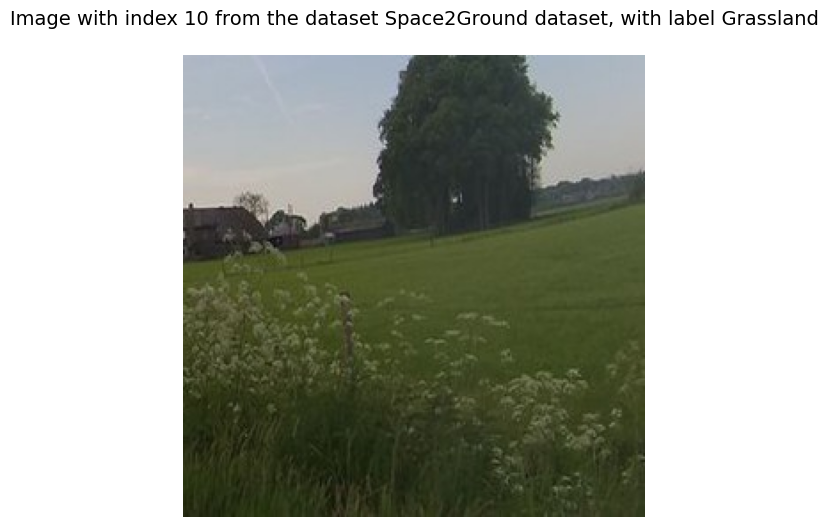

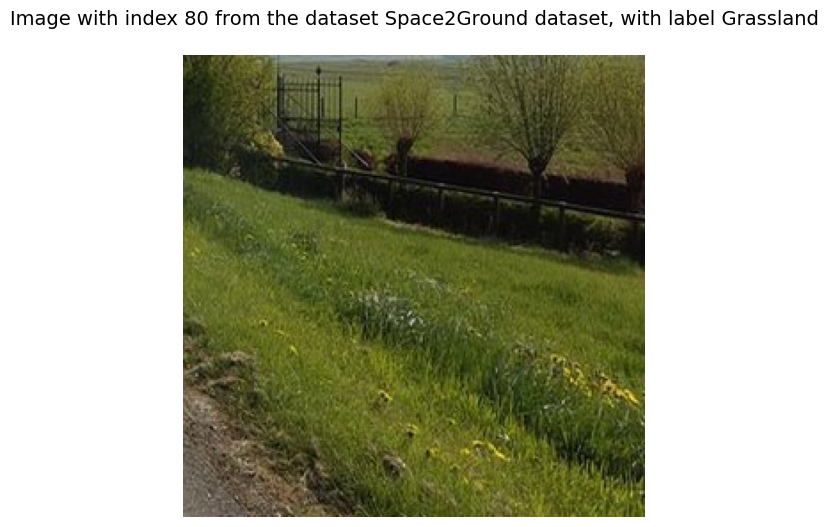

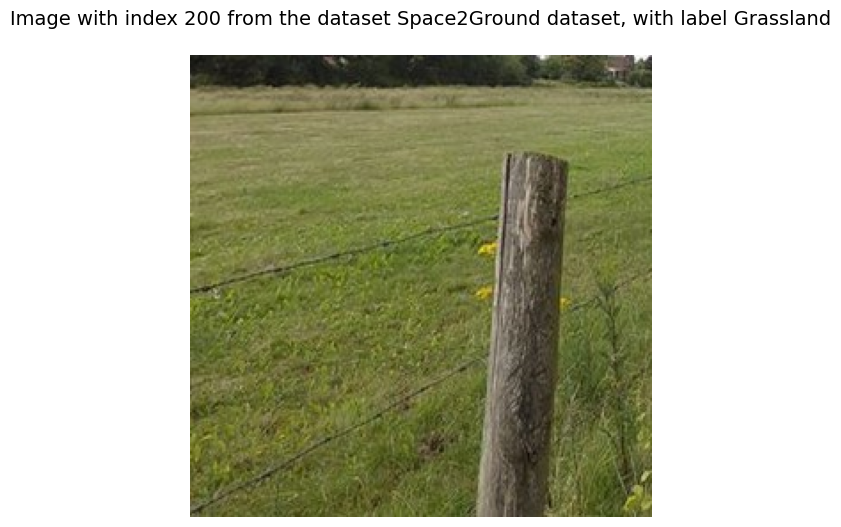

In [7]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

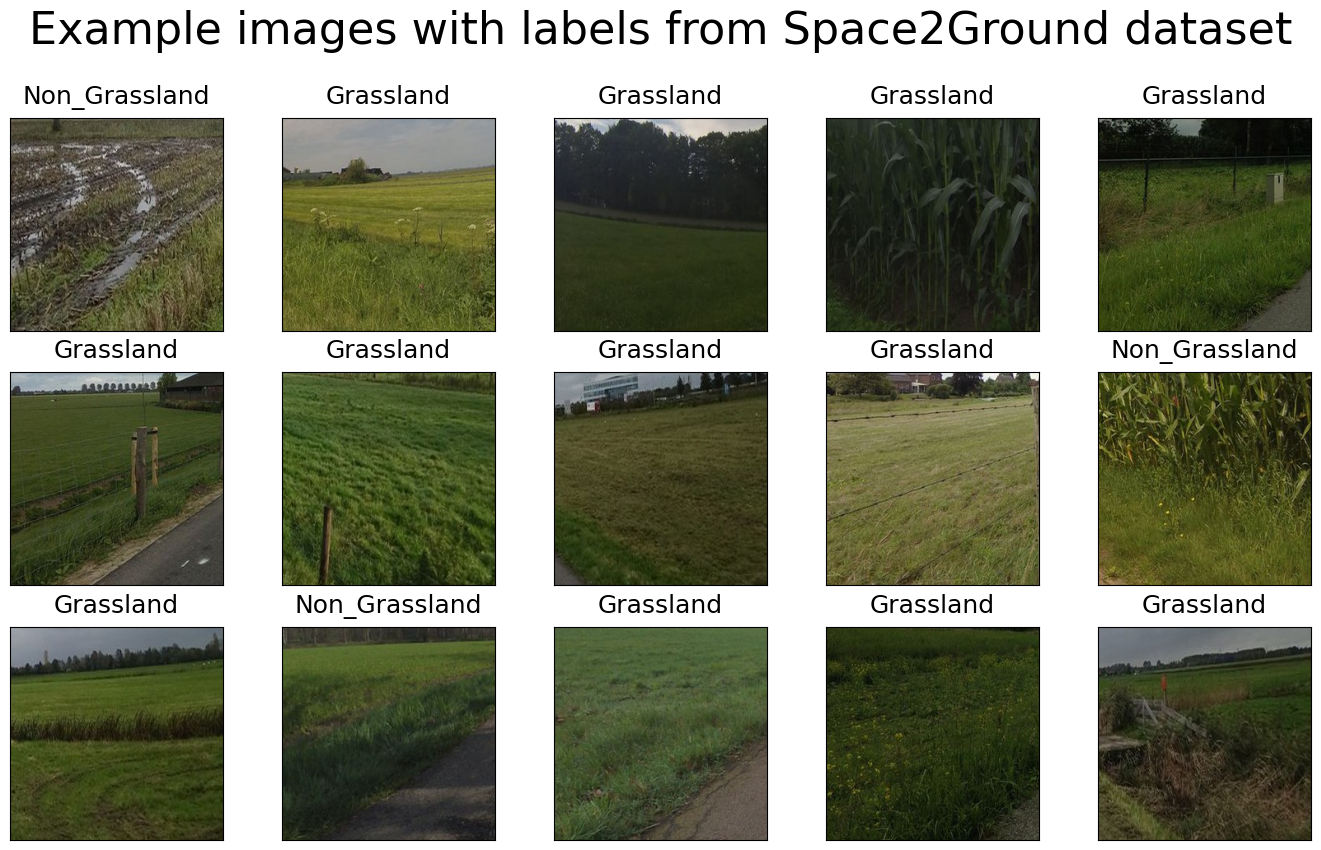

In [8]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [9]:
dataset.data_distribution_table()

,Label,Count
0,grassland,6946
1,non-grassland,902


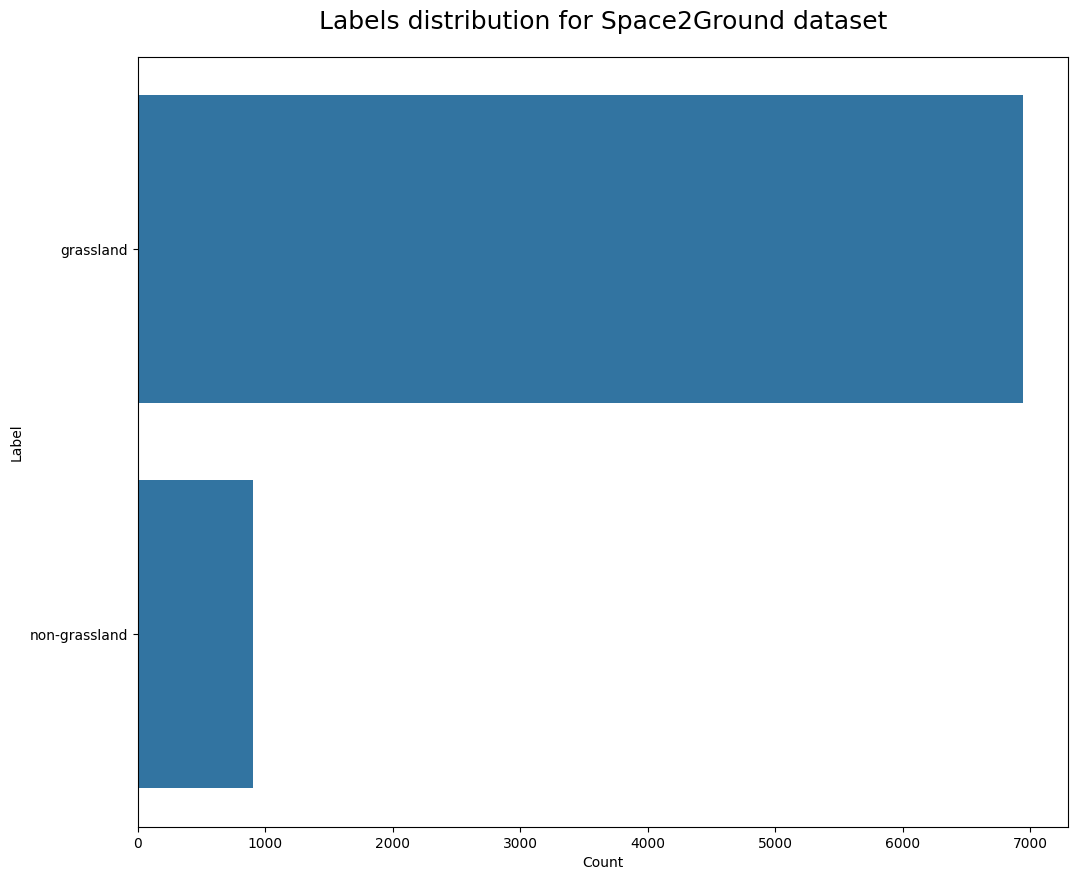

In [10]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [4]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/Space2Ground/StreetLevelImages/train/",
}

train_dataset = Space2GroundDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/Space2Ground/StreetLevelImages/test/",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = Space2GroundDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(7848, 2254)

## Setup and create the model for training

In [5]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/Space2Ground/StreetLevelImages/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-28 12:07:51,381 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-28 12:07:51,554 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [6]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-28 12:07:53,445 INFO Starting training.
training: 100%|██████████| 246/246 [01:01<00:00,  4.03it/s]
2025-05-28 12:08:54,628 INFO epoch: 1, time: 61, loss:  0.25715
testing on train set: 100%|██████████| 246/246 [00:21<00:00, 11.54it/s]
2025-05-28 12:09:17,728 INFO Accuracy:0.9178134556574924, Precision Micro:0.9178134556574924, Precision Macro:0.7923030341177288, Precision Weighted:0.925528356876129, Precision per Class:[0.61931291 0.96529316], Recall Micro:0.9178134556574924, Recall Macro:0.8402205356111097, Recall Weighted:0.9178134556574923, Recall per Class:[0.73946785 0.94097322], F1_score Micro:0.9178134556574918, F1_score Macro:0.8135279367528321, F1_score Weighted:0.9209230085299258, F1_score per Class:[0.67407782 0.95297806]
testing on validation set: 100%|██████████| 71/71 [00:06<00:00, 11.16it/s]
2025-05-28 12:09:24,099 INFO Accuracy:0.9099378881987578, Precision Micro:0.9099378881987578, Precision Macro:0.8248770981108224, Precision Weighted:0.9063809853874343, Prec

0.13361634360578872

## Predictions

2025-05-28 12:22:51,557 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/Space2Ground/StreetLevelImages/checkpoint.pth.tar
2025-05-28 12:22:51,762 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/Space2Ground/StreetLevelImages/checkpoint.pth.tar at epoch 11


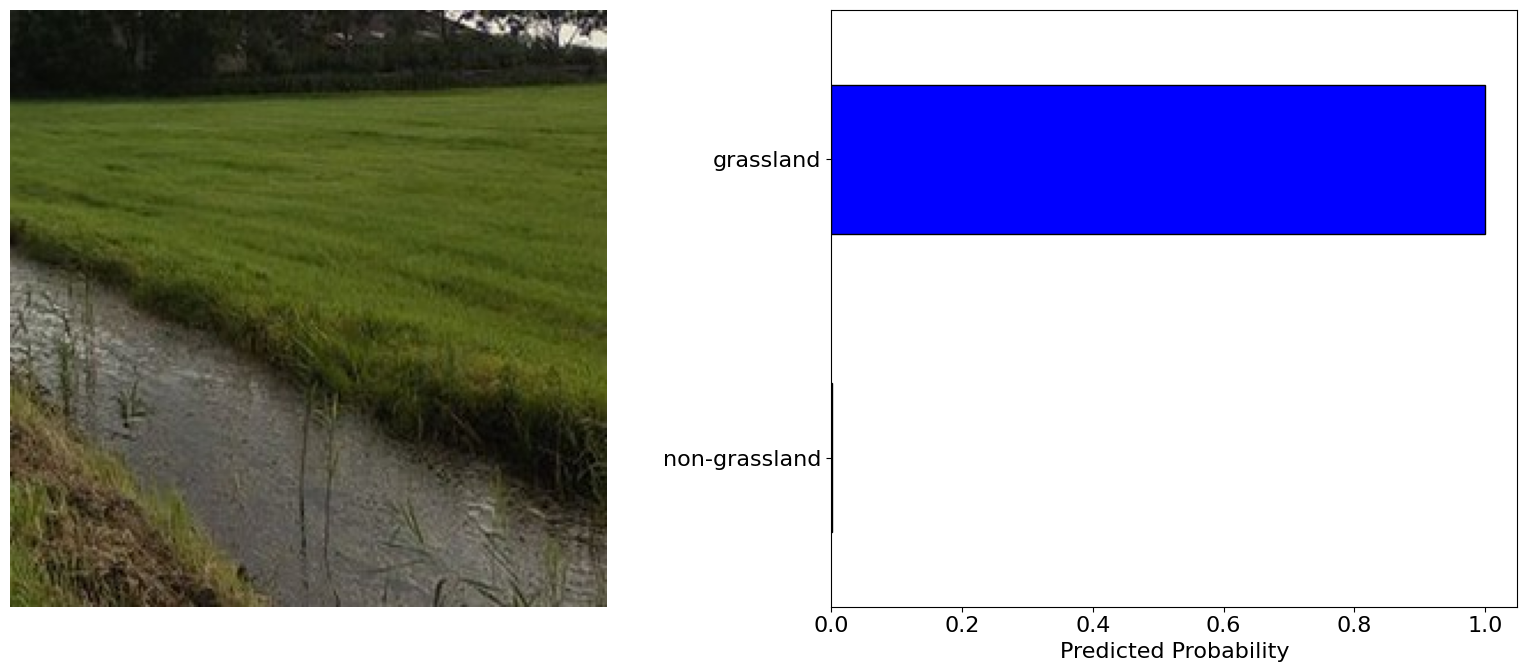

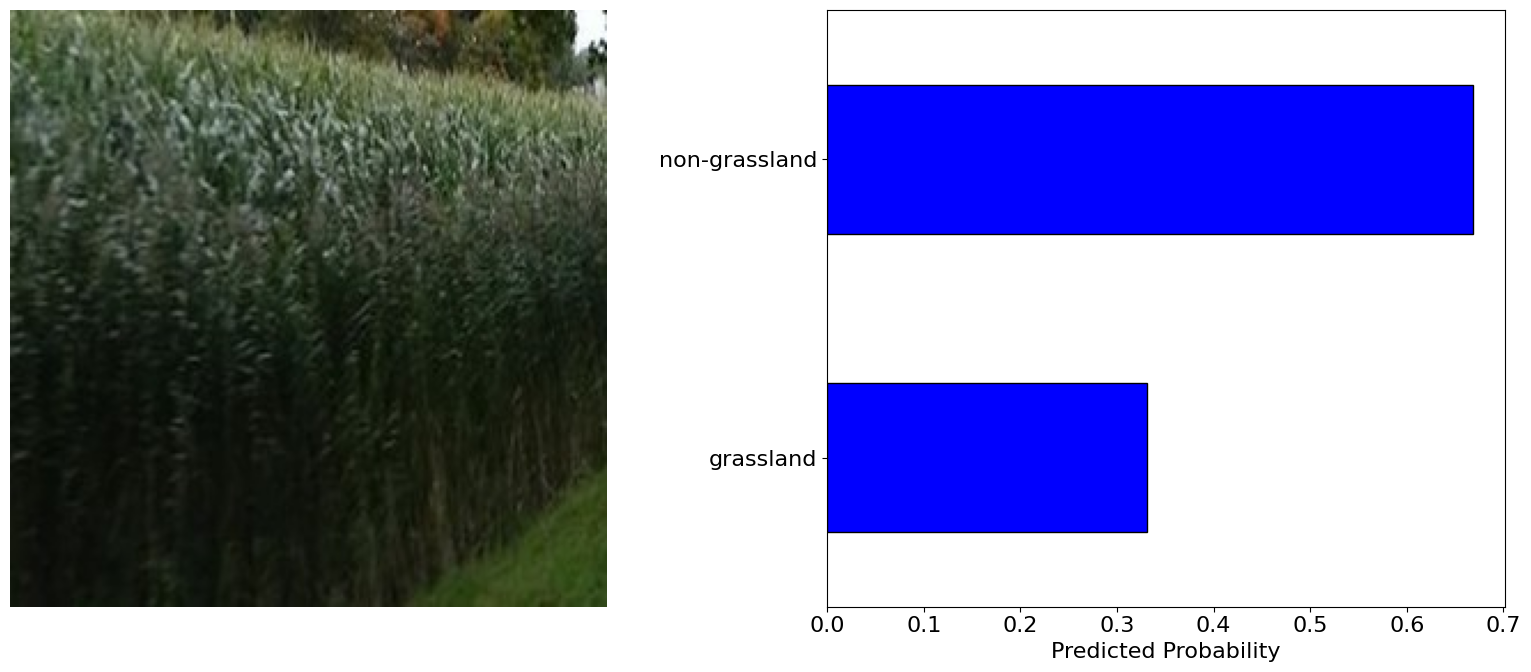

In [7]:
labels = ["non-grassland","grassland"]
transform = ResizeCenterCropToTensor()

model_path = "/home/dragik/data/FAIR_EO/experiments/Space2Ground/StreetLevelImages/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/Space2Ground/StreetLevelImages/test/Grassland/130717525772054_right.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/Space2Ground/StreetLevelImages/test/Non_Grassland/171169484919491_left.jpg')
fig = model.predict_image(image, labels, transform)